# 02 · Greedy and the loop

**The question.** Why does generated text sometimes get stuck repeating the same phrase?

**The claim.** Repetition loops are a *decoding* artifact, not a model defect. Greedy decoding, which always takes the single most likely token, cannot leave a high-probability groove once it enters one. Change the decoder and the loop goes away, with the model untouched.

**By the end** you will be able to measure a loop with distinct-n metrics, explain mechanically why greedy produces it, and fix it with a two-line change to the decoder.

*Outputs:* `outputs/figures/02_*.png` and `outputs/results/02_*.json`.

In [1]:
import inspect
import textwrap

import pandas as pd
import torch

from src.config import get_settings

S = get_settings()
SEED = S.seed
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
print(f"seed = {SEED}  (config/settings.yaml)")

from src.results import save_json
from src.visualisation import save_figure

seed = 42  (config/settings.yaml)


## 1. The simplest decoder

In [2]:
from src.decoders import greedy_pick

print(inspect.getsource(greedy_pick))

def greedy_pick(logits: Tensor) -> Tensor:
    """Return the argmax token for each row.

    Args:
        logits: ``(batch, vocab)`` scores (raw or already warped).

    Returns:
        ``(batch, 1)`` int64 token ids. Ties go to the lowest token id, like ``torch.argmax``.
    """
    return logits.argmax(dim=-1, keepdim=True)



One `argmax`. It looks like it should produce the *best* text: every step takes the model's favourite token.

## 2. Greedy on five open-ended prompts

In [3]:
from src.datasets import char_prompts
from src.decoders import Decoder, make_generator
from src.model import default_char_lm

model = default_char_lm()
N_NEW = S.generation.max_new_tokens  # characters
greedy = Decoder.greedy()
outputs = {}
for p in char_prompts("open"):
    ids = model.encode(p.text)
    outputs[p.text] = model.decode(greedy.generate(model, ids, N_NEW)[0, ids.size(1):])
    print(f"--- {p.text!r}\n{textwrap.fill(p.text + outputs[p.text], 110)}\n")
save_json("02_greedy_outputs", {"decoder": "greedy", "max_new_tokens": N_NEW, "outputs": outputs});

--- 'the keeper'
the keeper climbed the stairs for the market was held on the days when his boat came out of the sea. in the
morning and the small white boat that belonged to the sea. in the morning and the small white boat that
belonged to the sea. in the morning and the small white boat that belonged to the sea. in the morn

--- 'in the morning'
in the morning and the small white boat that belonged to the sea. in the morning and the small white boat that
belonged to the sea. in the morning and the small white boat that belonged to the sea. in the morning and the
small white boat that belonged to the sea. in the morning and the small white boat that belon

--- 'the sea was'
the sea was calm and the small white boat that belonged to the sea. in the morning and the small white boat
that belonged to the sea. in the morning and the small white boat that belonged to the sea. in the morning and
the small white boat that belonged to the sea. in the morning and the small white boat that

--- 

Five different openings, one destination: every prompt ends up circling *the same* sentence. That sentence is an **attractor** of greedy decoding on this model.

## 3. Measure it

Two numbers per text, computed on words:

- **distinct-2**: unique word pairs divided by all word pairs. 1.0 means no pair ever repeats; a tight loop drives it toward 0.
- **longest repeat**: the longest run of words that occurs at least twice.

In [4]:
from src.analysis import repetition_metrics

nucleus = Decoder.nucleus(S.decoding.default_top_p)
rows = []
for p in char_prompts("open"):
    ids = model.encode(p.text)
    out = nucleus.generate(model, ids, N_NEW, generator=make_generator(SEED))
    sampled = model.decode(out[0, ids.size(1):])
    for name, text in [("greedy", outputs[p.text]), (nucleus.label, sampled)]:
        rows.append({"prompt": p.text, "decoder": name, **repetition_metrics(text), "text": text})
metrics = pd.DataFrame(rows)
save_json("02_repetition_metrics", metrics)
metrics.pivot(index="prompt", columns="decoder", values=["distinct_2", "longest_repeat"]).round(2)

distinct_2        longest_repeat       
decoder        T=1, top-p=0.8 greedy T=1, top-p=0.8 greedy
prompt                                                    
in the morning           0.91   0.24            3.0   45.0
one winter               0.93   0.44            2.0   34.0
the fox                  0.78   0.38           14.0   37.0
the keeper               0.85   0.52            6.0   30.0
the sea was              0.93   0.24            2.0   45.0

## 4. Why greedy cannot escape

This model sees only the last 8 characters. Under greedy decoding the next character is therefore a *fixed function* of those 8 characters: same window in, same character out. That makes greedy decoding a finite-state machine, and a finite-state machine that runs long enough must revisit a state. The moment it does, everything after repeats forever.

`find_cycle` finds that first revisited window.

In [5]:
from src.analysis import find_cycle

cycles = []
for p in char_prompts("open"):
    ids = model.encode(p.text)
    seq = greedy.generate(model, ids, N_NEW)[0].tolist()
    start, period = find_cycle(seq, model.context)
    cycles.append({"prompt": p.text, "periodic_from_char": start, "period_chars": period,
                   "loop": model.decode(seq[start:start + period])})
cycles = pd.DataFrame(cycles)
save_json("02_cycles", {"context_chars": model.context, "cycles": cycles})
cycles

,prompt,periodic_from_char,period_chars,loop
0,the keeper,91,66,the sea. in the morning and the small white boat that belonged to
1,in the morning,0,66,in the morning and the small white boat that belonged to the sea.
2,the sea was,16,66,and the small white boat that belonged to the sea. in the morning
3,one winter,72,66,to the sea. in the morning and the small white boat that belonged
4,the fox,48,66,the sea. in the morning and the small white boat that belonged to


Real language models have far longer contexts, so their state space is astronomically larger and exact cycles are rarer. The mechanism is the same though: once a repeated phrase makes itself slightly more probable, greedy takes it, which makes it more probable again (Holtzman et al., 2020).

## 5. The model is *confident* inside the loop

inside the loop: mean p(chosen) = 0.91, lowest = 0.20, 84% of steps above 0.9


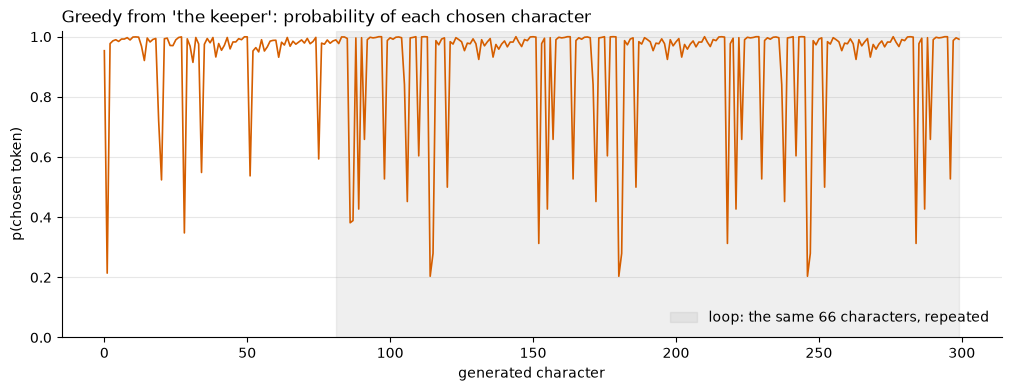

In [6]:
from src.analysis import token_probabilities
from src.visualisation import plot_token_trace

p = char_prompts("open")[0]
ids = model.encode(p.text)
seq = greedy.generate(model, ids, N_NEW)
trace = token_probabilities(model, seq, ids.size(1))
start, period = find_cycle(seq[0].tolist(), model.context)
loop_from = max(start - ids.size(1), 0)
inside = trace[trace["position"] >= loop_from]
confidence = {
    "prompt": p.text,
    "loop_starts_at_generated_char": loop_from,
    "mean_p_chosen_inside_loop": inside["p_chosen"].mean(),
    "min_p_chosen_inside_loop": inside["p_chosen"].min(),
    "share_of_loop_steps_above_0.9": (inside["p_chosen"] > 0.9).mean(),
    "trace": trace,
}
print(f"inside the loop: mean p(chosen) = {confidence['mean_p_chosen_inside_loop']:.2f}, "
      f"lowest = {confidence['min_p_chosen_inside_loop']:.2f}, "
      f"{confidence['share_of_loop_steps_above_0.9']:.0%} of steps above 0.9")
fig = plot_token_trace(trace, loop_start=loop_from,
                       title=f"Greedy from {p.text!r}: probability of each chosen character",
                       loop_label=f"loop: the same {period} characters, repeated")
save_figure(fig, "02_confidence_along_the_loop")
save_json("02_confidence_along_the_loop", confidence);

Every step inside the loop is the model's top choice, most of them by a wide margin. There is no point at which argmax "wants" to leave. The few dips are forks where the model *was* unsure, and greedy resolves every one of them the same way, every time.

## 6. The fix is the decoder

Two decoder changes, zero model changes:

- a **repetition penalty** (Keskar et al., 2019) shrinks the logits of characters already in the context;
- **nucleus sampling** samples from the top of the distribution instead of always taking the argmax.

,open_distinct_2,open_longest_repeat,open_diversity
decoder,,,
greedy,0.36,38.20,0.07
"greedy, rep=1.3",0.70,16.20,0.14
"T=1, top-p=0.8",0.86,5.64,0.66


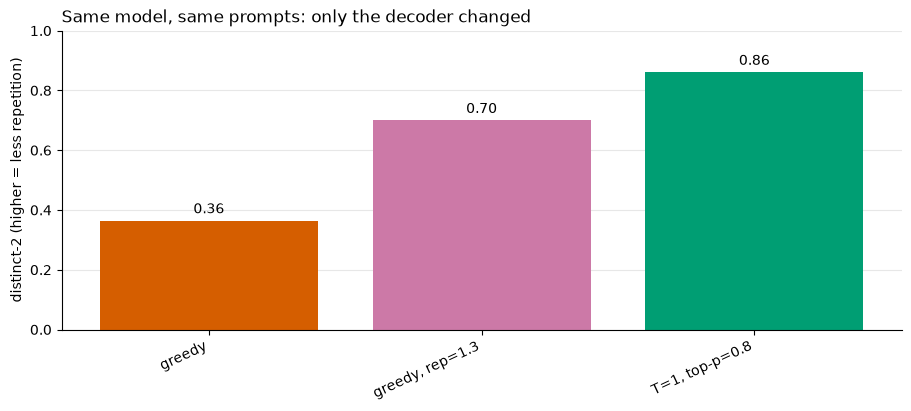

In [7]:
from src.evaluation import run_arena, summarize_arena
from src.visualisation import plot_decoder_bars

strategies = [Decoder.greedy(), Decoder.greedy(S.decoding.default_repetition_penalty), nucleus]
arena = run_arena(model, char_prompts("open"), strategies, n_samples=S.generation.n_samples,
                  max_new_tokens=N_NEW, seed=SEED, score_quality=False)
summary = summarize_arena(arena, S.generation.n_samples)
cols = ["open_distinct_2", "open_longest_repeat", "open_diversity"]
fig = plot_decoder_bars(summary, "open_distinct_2", ylabel="distinct-2 (higher = less repetition)",
                        title="Same model, same prompts: only the decoder changed", ylim=(0, 1))
save_figure(fig, "02_repetition_by_decoder")
save_json("02_repetition_by_decoder", {
    "n_samples": S.generation.n_samples, "max_new_tokens": N_NEW,
    "summary": summary[cols], "samples": arena[["prompt", "decoder", "sample", "completion"]],
})
summary[cols].round(2)

`open_diversity` pools word pairs across the samples for each prompt. A deterministic decoder says the same thing on every run, so its diversity across runs is low no matter what is inside each text.

## 7. The same failure in a real model

In [8]:
from huggingface_hub.utils import logging as hub_logging
from transformers.utils import logging as hf_logging

from src.model import load_model

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error()
hf = load_model("hf")  # distilgpt2: ~350 MB on first use, cached afterwards

Greedy on a small real model does not always loop in words. "The old lighthouse keeper" produces one clean sentence and then fills the rest of its budget with blank lines, a loop that word-level metrics cannot see. On the prompts below it loops in plain sight. The decoders are the same three as above.

In [9]:
from src.datasets import hf_prompts

hf_rows = []
for p in hf_prompts("open")[::2]:  # "In the morning, the sea was" and "The meaning of life is"
    hf_ids = hf.encode(p.text)
    for decoder in [Decoder.greedy(), Decoder.greedy(1.3), Decoder.nucleus(0.9)]:
        out = decoder.generate(hf, hf_ids, 60, eos_token_id=hf.eos_token_id,
                               generator=make_generator(SEED))
        text = hf.decode(out[0, hf_ids.size(1):])
        m = repetition_metrics(text)
        hf_rows.append({"prompt": p.text, "decoder": decoder.label, **m, "text": text})
        print(f"--- {decoder.label}  (distinct-2 {m['distinct_2']:.2f}, "
              f"longest repeat {m['longest_repeat']:.0f} words)")
        print(textwrap.fill(p.text + text, 110), "\n")
save_json("02_distilgpt2_loop", {"model": hf.name, "max_new_tokens": 60, "results": hf_rows});

--- greedy  (distinct-2 0.13, longest repeat 42 words)
In the morning, the sea was rising, and the sea was rising. The sea was rising. The sea was rising. The sea
was rising. The sea was rising. The sea was rising. The sea was rising. The sea was rising. The sea was
rising. The sea was rising. The sea was rising. The sea 



--- greedy, rep=1.3  (distinct-2 1.00, longest repeat 0 words)
In the morning, the sea was rising. The sun had risen and it looked like a great storm of wind blowing through
its sails." "I'm not sure what happened to my wife," she said with an expression that seemed as if her
husband's face would be covered in tears from his eyes when he heard them say "Oh 



--- T=1, top-p=0.9  (distinct-2 0.98, longest repeat 2 words)
In the morning, the sea was solid and cloudy and caused massive flooding.    When the low wind blew out,
people rushed into their homes. Soon after the storm began, some residents resorted to flying blankets and
heat blankets. People reacted as wind slowly rose from their homes, leaving only burning stoves. It 



--- greedy  (distinct-2 0.13, longest repeat 46 words)
The meaning of life is to be understood as a whole, and to be understood as a whole, and to be understood as a
whole, and to be understood as a whole, and to be understood as a whole, and to be understood as a whole, and
to be understood as a whole, and to be understood as 



--- greedy, rep=1.3  (distinct-2 1.00, longest repeat 1 words)
The meaning of life is to be understood as a whole, and the existence of it can only become part or parcel.
This means that we are not in any position to say what our lives should look like without being able (or at
least understanding) how they might actually feel when you're living with them - but rather 



--- T=1, top-p=0.9  (distinct-2 0.94, longest repeat 3 words)
The meaning of life is not bound by a rule; in actual life, it is bound by something else and would not be
necessarily an object of matter. Once inside the dog's mind, you can say that there is a limited knowledge of
what is outside of the dog's mind, and only that those things have that knowledge 



## What this bought you

- Greedy decoding loops on open-ended prompts, on both models, and distinct-2 and longest-repeat turn that into a number.
- The loop is mechanical: a deterministic decoder over a bounded state *must* cycle, and inside the cycle the model is confident at almost every step.
- The fix is in the decoder. A repetition penalty or sampling breaks the loop without touching a single weight.

Next: [03 · Temperature is one line](03_temperature_is_one_line.ipynb), the knob that interpolates between greedy and chaos.